# Práctica final Python: Accidentalidad en Madrid (2024)

A partir de los datos abiertos de accidentes de tráfico del Ayuntamiento de Madrid en 2024, se realiza un Análisis Exploratorio de Datos (EDA) para responder a una pregunta de negocio y se entrena un modelo de **Regresión Logística** que predice si un implicado da positivo en alcohol.

## Índice

1. Librerías
2. Descripción de los datos
3. Preparación y limpieza de los datos
4. Análisis univariante
5. Análisis bivariante y pregunta de negocio
6. Pregunta adicional
7. Conclusiones
8. Modelo de Regresión Logística

## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from models import AlcoholLogisticModel

### Pregunta de negocio

**¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?**

## 2. Descripción de los datos

Carga del dataset, tamaño, primera vista, duplicados y tipos de datos.

In [2]:
db = pd.read_csv("2024_Accidentalidad.csv",sep=";")

In [3]:
# Tamaño del dataset (filas, columnas)
db.shape

(49340, 19)

In [4]:
# Primera vista del dataset
db.head(10)

,num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,cod_lesividad,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga
0,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,Hombre,2.0,Ingreso inferior o igual a 24 horas,444913.0,4481427.0,N,NaN
1,2023S040280,04/01/2024,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Turismo,Conductor,De 55 a 59 años,Mujer,14.0,Sin asistencia sanitaria,444913.0,4481427.0,N,NaN
2,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,Hombre,7.0,Asistencia sanitaria sólo en el lugar del acci...,440123.0,4475170.0,N,NaN
3,2023S040309,15/02/2024,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,Hombre,14.0,Sin asistencia sanitaria,440123.0,4475170.0,N,NaN
4,2023S040310,18/02/2024,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión lateral,Despejado,Turismo,Conductor,De 25 a 29 años,Hombre,NaN,NaN,440137.0,4475721.0,N,NaN
5,2023S040310,18/02/2024,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión lateral,Despejado,Turismo,Conductor,De 55 a 59 años,Hombre,NaN,NaN,440137.0,4475721.0,N,NaN
6,2023S040312,25/02/2024,17:20:00,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión lateral,Despejado,Camión rígido,Conductor,De 25 a 29 años,Hombre,14.0,Sin asistencia sanitaria,440709.0,4480102.0,N,NaN
7,2023S040312,25/02/2024,17:20:00,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión lateral,Despejado,Maquinaria de obras,Conductor,De 50 a 54 años,Hombre,14.0,Sin asistencia sanitaria,440709.0,4480102.0,N,NaN
8,2023S040316,07/03/2024,14:25:00,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Furgoneta,Conductor,De 60 a 64 años,Hombre,NaN,NaN,433983.0,4468473.0,N,NaN
9,2023S040316,07/03/2024,14:25:00,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Turismo,Conductor,De 25 a 29 años,Hombre,NaN,NaN,433983.0,4468473.0,N,NaN


In [5]:
num_duplicados = db.duplicated().sum()

In [6]:
print(num_duplicados)

2053


In [7]:
# Eliminamos los registros duplicados
db.drop_duplicates(inplace=True)

In [8]:
db.shape

(47287, 19)

In [9]:
# Tipo de dato y número de valores no nulos de cada columna
db.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47287 entries, 0 to 49339
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   num_expediente        47287 non-null  object 
 1   fecha                 47287 non-null  object 
 2   hora                  47287 non-null  object 
 3   localizacion          47287 non-null  object 
 4   numero                47287 non-null  object 
 5   cod_distrito          47287 non-null  int64  
 6   distrito              47287 non-null  object 
 7   tipo_accidente        47282 non-null  object 
 8   estado_meteorológico  41708 non-null  object 
 9   tipo_vehiculo         46898 non-null  object 
 10  tipo_persona          47287 non-null  object 
 11  rango_edad            47287 non-null  object 
 12  sexo                  47287 non-null  object 
 13  cod_lesividad         26954 non-null  float64
 14  lesividad             26954 non-null  object 
 15  coordenada_x_utm      47

Vemos que hay muchos datos nulos en las variables de lesividad y en el positivo en droga.

In [10]:
# Nombre de las columnas
db.columns

Index(['num_expediente', 'fecha', 'hora', 'localizacion', 'numero',
       'cod_distrito', 'distrito', 'tipo_accidente', 'estado_meteorológico',
       'tipo_vehiculo', 'tipo_persona', 'rango_edad', 'sexo', 'cod_lesividad',
       'lesividad', 'coordenada_x_utm', 'coordenada_y_utm', 'positiva_alcohol',
       'positiva_droga'],
      dtype='object')

## 3. Preparación y limpieza de los datos

Eliminación de columnas no relevantes, tratamiento de valores nulos, transformación de fecha y hora y revisión de los outliers de las coordenadas.

El positivo en droga podría ser relevante para la pregunta de negocio, pero solo tiene 203 registros con valor, así que eliminamos la columna.

In [11]:
db.drop(labels='positiva_droga', axis=1, inplace=True)

In [12]:
# El número de expediente no es relevante para el análisis
db.drop(labels='num_expediente', axis=1, inplace=True)

In [13]:
db.columns

Index(['fecha', 'hora', 'localizacion', 'numero', 'cod_distrito', 'distrito',
       'tipo_accidente', 'estado_meteorológico', 'tipo_vehiculo',
       'tipo_persona', 'rango_edad', 'sexo', 'cod_lesividad', 'lesividad',
       'coordenada_x_utm', 'coordenada_y_utm', 'positiva_alcohol'],
      dtype='object')

In [14]:
# Nulos que quedan tras eliminar las dos columnas
db.isnull().sum()

fecha                       0
hora                        0
localizacion                0
numero                      0
cod_distrito                0
distrito                    0
tipo_accidente              5
estado_meteorológico     5579
tipo_vehiculo             389
tipo_persona                0
rango_edad                  0
sexo                        0
cod_lesividad           20333
lesividad               20333
coordenada_x_utm            6
coordenada_y_utm            6
positiva_alcohol          167
dtype: int64

In [15]:
# Tipo de accidente, tipo de vehículo, coordenadas y positivo en alcohol tienen pocos nulos: los eliminamos
db = db.dropna(subset=["tipo_accidente", "tipo_vehiculo", "coordenada_x_utm", "coordenada_y_utm", "positiva_alcohol"])

In [16]:
db.isnull().sum()

fecha                       0
hora                        0
localizacion                0
numero                      0
cod_distrito                0
distrito                    0
tipo_accidente              0
estado_meteorológico     5515
tipo_vehiculo               0
tipo_persona                0
rango_edad                  0
sexo                        0
cod_lesividad           19877
lesividad               19877
coordenada_x_utm            0
coordenada_y_utm            0
positiva_alcohol            0
dtype: int64

In [17]:
# Agrupamos la colisión frontal, la fronto-lateral y la lateral en una sola categoría: colisión doble
colisiones_dobles = ['Colisión frontal', 'Colisión fronto-lateral', 'Colisión lateral']

In [18]:
db['tipo_accidente'] = db['tipo_accidente'].replace(colisiones_dobles, 'Colisión doble')

La **lesividad** tiene muchos valores nulos (los vemos en la tabla anterior). No sabemos si esas personas necesitaron asistencia o no, así que les ponemos el valor **77 - Se desconoce**. El código de lesividad queda como número entero.

In [19]:
# Los nulos de lesividad pasan a "77 - Se desconoce"
db['cod_lesividad'] = db['cod_lesividad'].fillna(77).astype(int)
db['lesividad'] = db['lesividad'].fillna("Se desconoce")

In [20]:
db.isnull().sum()

fecha                      0
hora                       0
localizacion               0
numero                     0
cod_distrito               0
distrito                   0
tipo_accidente             0
estado_meteorológico    5515
tipo_vehiculo              0
tipo_persona               0
rango_edad                 0
sexo                       0
cod_lesividad              0
lesividad                  0
coordenada_x_utm           0
coordenada_y_utm           0
positiva_alcohol           0
dtype: int64

In [21]:
# Moda del estado meteorológico, para rellenar sus nulos
meteorologico_moda = db.estado_meteorológico.mode()[0]

In [22]:
meteorologico_moda

'Despejado'

Al ser pocos registros, para no eliminarlos sacamos la **moda** del estado meteorológico y la imputamos a la variable *estado meteorológico*.

In [23]:
db["estado_meteorológico"] = db["estado_meteorológico"].fillna(meteorologico_moda)

In [24]:
# Comprobamos que ya no quedan nulos
db.isnull().sum()

fecha                   0
hora                    0
localizacion            0
numero                  0
cod_distrito            0
distrito                0
tipo_accidente          0
estado_meteorológico    0
tipo_vehiculo           0
tipo_persona            0
rango_edad              0
sexo                    0
cod_lesividad           0
lesividad               0
coordenada_x_utm        0
coordenada_y_utm        0
positiva_alcohol        0
dtype: int64

In [25]:
# Tipo de dato de cada columna
db.dtypes

fecha                    object
hora                     object
localizacion             object
numero                   object
cod_distrito              int64
distrito                 object
tipo_accidente           object
estado_meteorológico     object
tipo_vehiculo            object
tipo_persona             object
rango_edad               object
sexo                     object
cod_lesividad             int32
lesividad                object
coordenada_x_utm        float64
coordenada_y_utm        float64
positiva_alcohol         object
dtype: object

In [26]:
# Pasamos la fecha a tipo fecha, creamos la columna del mes y quitamos la fecha (el dataset es de 2024)
db['fecha'] = pd.to_datetime(db['fecha'], format="%d/%m/%Y")
db['mes'] = db['fecha'].dt.month
db.drop(labels='fecha', axis=1, inplace=True)

In [27]:
# Nos quedamos solo con la hora entera (14, 15, 16...)
db['hora'] = pd.to_datetime(db['hora'], format="%H:%M:%S").dt.hour

In [28]:
# Comprobamos el cambio de la hora y el mes
db.dtypes

hora                      int32
localizacion             object
numero                   object
cod_distrito              int64
distrito                 object
tipo_accidente           object
estado_meteorológico     object
tipo_vehiculo            object
tipo_persona             object
rango_edad               object
sexo                     object
cod_lesividad             int32
lesividad                object
coordenada_x_utm        float64
coordenada_y_utm        float64
positiva_alcohol         object
mes                       int32
dtype: object

### Outliers de las coordenadas

Revisamos si hay valores atípicos en las coordenadas UTM de los accidentes.

In [29]:
# Resumen de las coordenadas: mínimo, máximo, cuartiles...
db[['coordenada_x_utm', 'coordenada_y_utm']].describe()

,coordenada_x_utm,coordenada_y_utm
count,46769.000000,4.676900e+04
mean,442077.403729,4.474674e+06
std,3465.267985,3.950409e+03
min,429177.000000,4.463657e+06
25%,439911.000000,4.471638e+06
50%,441750.000000,4.474668e+06
75%,443988.000000,4.477470e+06
max,454754.000000,4.492208e+06


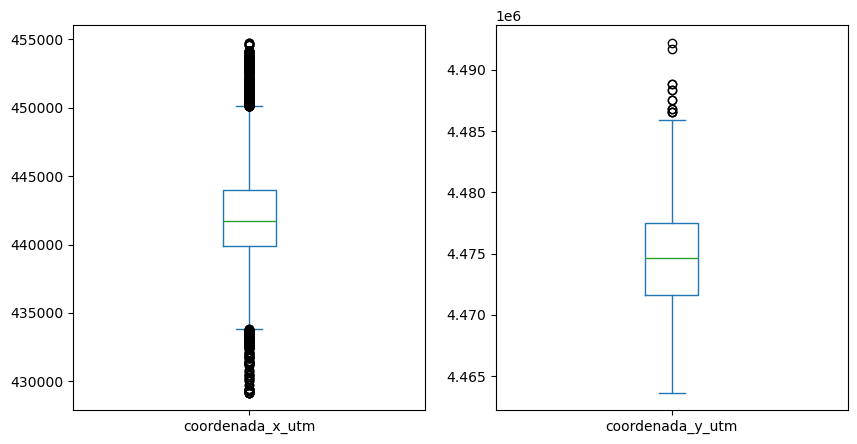

In [30]:
# Boxplot de cada coordenada para ver los valores atípicos
db[['coordenada_x_utm', 'coordenada_y_utm']].plot.box(subplots=True, figsize=(10, 5))
plt.show()

In [31]:
# Valores atípicos de la coordenada X según la regla del boxplot (1,5 veces el rango intercuartílico)
q1 = db['coordenada_x_utm'].quantile(0.25)
q3 = db['coordenada_x_utm'].quantile(0.75)
iqr = q3 - q1
atipicos_x = db[(db['coordenada_x_utm'] < q1 - 1.5 * iqr) | (db['coordenada_x_utm'] > q3 + 1.5 * iqr)]

# ¿De qué distritos son?
atipicos_x['distrito'].value_counts()

distrito
BARAJAS                438
SAN BLAS-CANILLEJAS    294
MONCLOA-ARAVACA        230
VICÁLVARO              208
LATINA                  88
VILLA DE VALLECAS       55
CIUDAD LINEAL           10
HORTALEZA                4
FUENCARRAL-EL PARDO      3
CARABANCHEL              2
Name: count, dtype: int64

En el boxplot vemos muchos valores atípicos en la coordenada **X** y muy pocos en la **Y**. Los de la X son, sobre todo, de Barajas, San Blas-Canillejas, Moncloa-Aravaca y Vicálvaro.

Como las coordenadas no se usan ni en el análisis ni en el modelo, **los mantenemos**.

## 4. Análisis univariante

Estudio de cada variable por separado para conocer cómo se distribuyen los datos.

In [32]:
db.tipo_accidente.value_counts(normalize=True)

tipo_accidente
Colisión doble                  0.458145
Alcance                         0.250337
Choque contra obstáculo fijo    0.100109
Atropello a persona             0.062092
Caída                           0.056384
Colisión múltiple               0.046655
Otro                            0.016314
Solo salida de la vía           0.005067
Vuelco                          0.003378
Atropello a animal              0.001518
Name: proportion, dtype: float64

La **colisión doble** y el **alcance** se llevan la palma en porcentaje de tipo de accidente.

<Axes: ylabel='estado_meteorológico'>

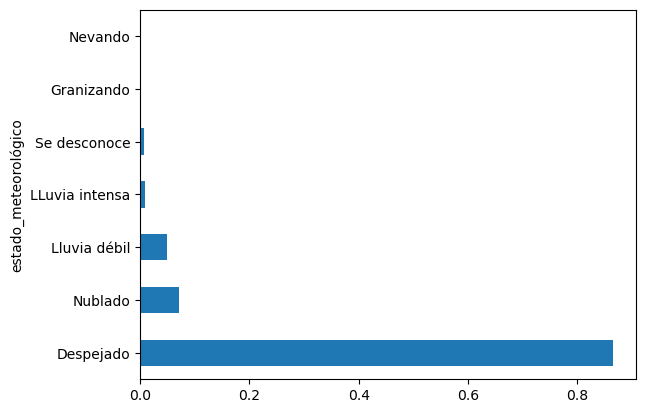

In [33]:
db.estado_meteorológico.value_counts(normalize=True).plot.barh()

La mayoría de los accidentes se producen con el día **despejado**.

In [34]:
db.tipo_vehiculo.value_counts(normalize=True)

tipo_vehiculo
Turismo                              0.681883
Motocicleta hasta 125cc              0.069897
Furgoneta                            0.068058
Motocicleta > 125cc                  0.038423
Autobús                              0.031452
Camión rígido                        0.024418
Todo terreno                         0.017447
Bicicleta                            0.017319
VMU eléctrico                        0.016421
Ciclomotor                           0.009942
Bicicleta EPAC (pedaleo asistido)    0.005559
Tractocamión                         0.004512
Maquinaria de obras                  0.003827
Otros vehículos con motor            0.003485
Vehículo articulado                  0.001796
Autobús articulado                   0.001604
Cuadriciclo ligero                   0.000898
Sin especificar                      0.000706
Autobus EMT                          0.000556
Cuadriciclo no ligero                0.000406
Ciclo                                0.000363
Autocaravana        

Los **turismos** fueron por una amplia mayoría los más implicados en los accidentes.

<Axes: ylabel='count'>

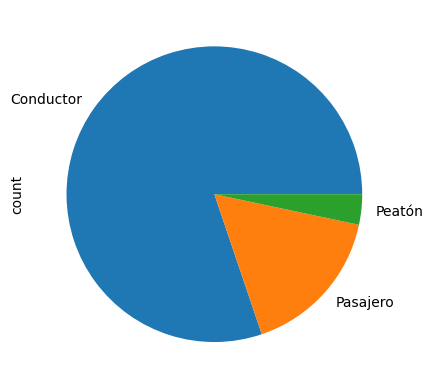

In [35]:
db.tipo_persona.value_counts().plot.pie()

La mayoría de implicados son **conductores**, seguidos de los pasajeros.

<Axes: ylabel='count'>

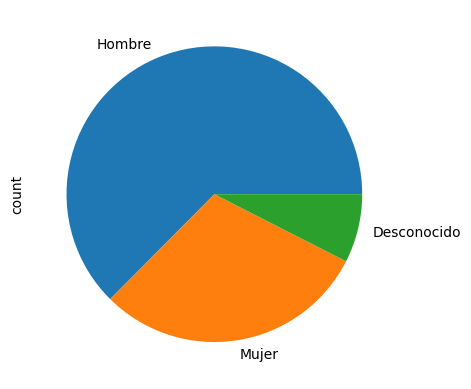

In [36]:
db.sexo.value_counts().plot.pie()

Los **hombres** se llevan la palma. También vemos una pequeña proporción de datos desconocidos, pero teniendo en cuenta la mayoría que tenemos de hombres no parece relevante.

In [37]:
db.distrito.value_counts(normalize=True)

distrito
PUENTE DE VALLECAS     0.080203
CHAMARTÍN              0.072976
CARABANCHEL            0.070346
SALAMANCA              0.067032
CIUDAD LINEAL          0.061344
CENTRO                 0.057645
ARGANZUELA             0.054780
RETIRO                 0.051957
FUENCARRAL-EL PARDO    0.050332
MONCLOA-ARAVACA        0.048451
TETUÁN                 0.047360
LATINA                 0.046633
SAN BLAS-CANILLEJAS    0.046227
CHAMBERÍ               0.044688
USERA                  0.041865
HORTALEZA              0.036477
VILLAVERDE             0.033655
MORATALAZ              0.028587
VILLA DE VALLECAS      0.024589
VICÁLVARO              0.017832
BARAJAS                0.017020
Name: proportion, dtype: float64

Vemos que los accidentes están muy repartidos en función del **distrito**, por lo que no podemos sacar una conclusión clara.

In [38]:
db.rango_edad.value_counts(normalize=True)

rango_edad
De 45 a 49 años    0.105583
De 30 a 34 años    0.101777
De 25 a 29 años    0.100387
De 40 a 44 años    0.099232
De 35 a 39 años    0.096859
De 50 a 54 años    0.095469
Desconocido        0.076504
De 55 a 59 años    0.073745
De 21 a 24 años    0.067930
De 60 a 64 años    0.051594
De 18 a 20 años    0.031688
Más de 74 años     0.025123
De 65 a 69 años    0.024824
De 70 a 74 años    0.015480
De 15 a 17 años    0.009451
Menor de 5 años    0.009173
De 10 a 14 años    0.008938
De 6 a 9 años      0.006243
Name: proportion, dtype: float64

Lo mismo nos pasa con la **edad**, aunque nos cuadran los datos, ya que la persona más implicada es el conductor y la mayoría de datos están agrupados en la mayoría de edad.

In [39]:
db.lesividad.value_counts(normalize=True)

lesividad
Se desconoce                                                 0.425047
Sin asistencia sanitaria                                     0.338151
Asistencia sanitaria sólo en el lugar del accidente          0.121854
Ingreso inferior o igual a 24 horas                          0.039471
Atención en urgencias sin posterior ingreso                  0.028288
Asistencia sanitaria inmediata en centro de salud o mutua    0.023498
Ingreso superior a 24 horas                                  0.011974
Asistencia sanitaria ambulatoria con posterioridad           0.011097
Fallecido 24 horas                                           0.000620
Name: proportion, dtype: float64

Casi la mitad de los registros no tienen dato de lesividad (*Se desconoce*). Del resto, la mayoría no necesitó asistencia sanitaria y los accidentes **graves** (ingreso superior a 24 horas o fallecidos) son muy pocos. Por fortuna, la gravedad de los accidentes no es elevada.

In [40]:
db.mes.value_counts()

mes
10    4412
12    4366
11    4293
5     4222
4     4107
6     4022
9     3967
2     3799
3     3783
1     3645
7     3602
8     2551
Name: count, dtype: int64

Los accidentes bajan claramente en **agosto**, el mes con menos.

In [41]:
db.hora.value_counts(normalize=True)

hora
19    0.072142
18    0.071051
14    0.069020
15    0.067374
17    0.064166
20    0.061964
13    0.060489
16    0.055956
12    0.053283
9     0.053112
21    0.045714
11    0.044602
8     0.044538
10    0.039984
22    0.035750
23    0.028587
7     0.026663
0     0.023841
1     0.020291
6     0.017212
2     0.013727
5     0.011311
3     0.010669
4     0.008553
Name: proportion, dtype: float64

In [42]:
db.hora.value_counts()

hora
19    3374
18    3323
14    3228
15    3151
17    3001
20    2898
13    2829
16    2617
12    2492
9     2484
21    2138
11    2086
8     2083
10    1870
22    1672
23    1337
7     1247
0     1115
1      949
6      805
2      642
5      529
3      499
4      400
Name: count, dtype: int64

Aquí lo que se puede apreciar es que **de madrugada hay muchos menos accidentes**.

In [43]:
db.positiva_alcohol.value_counts(normalize=True)

positiva_alcohol
N    0.969381
S    0.030619
Name: proportion, dtype: float64

Solo un **3 %** de los implicados dio **positivo en alcohol**: los datos están muy **desbalanceados**. Hay que tenerlo en cuenta en el modelo, porque uno que dijera siempre «negativo» acertaría el 97 % de las veces sin detectar ningún positivo.

### Resumen del análisis univariante

De lo que hemos visto, en los accidentes por el momento la mayoría de datos se concentran:

- cuando hacía **buen tiempo**,
- los implicados eran **conductores**,
- **hombres**,
- en un **turismo**,
- fuera de **agosto**,
- y en horas **'laborables'**.

## 5. Análisis bivariante y pregunta de negocio

Casi todas las variables son categóricas, así que no usamos una matriz de correlación: las relaciones entre variables las vemos cruzándolas con tablas y gráficos para responder a la pregunta de negocio:

**¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?**

### Franja horaria de los accidentes graves

Primero vamos a ver en qué franja horaria se producen los accidentes con **ingreso superior a 24 horas o fallecidos**.

In [44]:
# Accidentes graves: ingreso superior a 24 horas o fallecidos
accidentes_graves = db[(db['lesividad'] == 'Fallecido 24 horas') | (db['lesividad'] == 'Ingreso superior a 24 horas')]

In [45]:
accidentes_graves_por_hora = accidentes_graves['hora'].value_counts().sort_index()

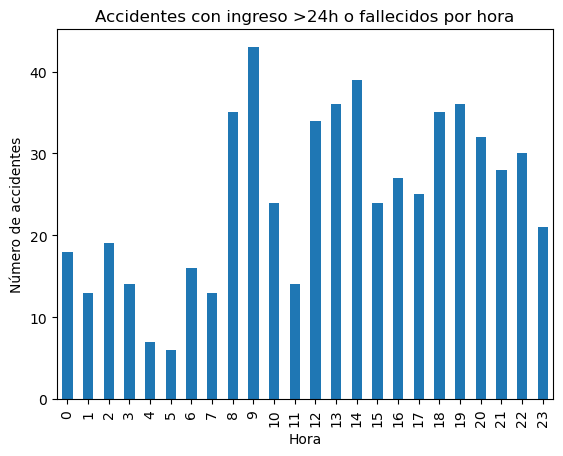

In [46]:
accidentes_graves_por_hora.plot.bar()
plt.title('Accidentes con ingreso >24h o fallecidos por hora')
plt.xlabel('Hora')
plt.ylabel('Número de accidentes')
plt.show()

Vemos que hay **tres tramos diferenciados: 8-9, 12-14 y 18-22**.

Vamos a ver todos los accidentes por hora:

In [47]:
accidentes_totales_por_hora = db['hora'].value_counts().sort_index()

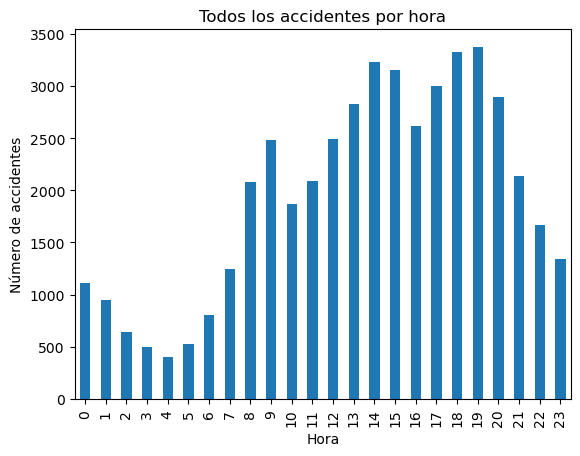

In [48]:
accidentes_totales_por_hora.plot.bar()
plt.title('Todos los accidentes por hora')
plt.xlabel('Hora')
plt.ylabel('Número de accidentes')
plt.show()

Aquí vemos que los accidentes se concentran **entre las 14 y las 20 horas**: es el tramo con más accidentes.

### Definición del *tramo negro* (17h - 21h)

Teniendo en cuenta los datos (entre las 14 y las 20 se concentran los accidentes y, por la tarde, los más graves —hospitalización mayor de 24 horas o fallecidos— se producen entre las 18-22), podemos definir como **tramo negro 17 - 21** (para tener más datos de muestra).

In [49]:
# Tramo negro: de 17h a 21h
tramo_negro = db[(db['hora'] >= 17) & (db['hora'] <= 21)]

In [50]:
# Porcentaje de los accidentes graves que se producen en el tramo negro
graves_tramo_negro = accidentes_graves[(accidentes_graves['hora'] >= 17) & (accidentes_graves['hora'] <= 21)]
len(graves_tramo_negro) / len(accidentes_graves) * 100

26.485568760611205

En el tramo negro se concentra **una cuarta parte** de los accidentes graves.

In [51]:
# Contamos los accidentes del tramo negro según el positivo en alcohol y el sexo
pivot_alcohol_sexo = pd.pivot_table(data=tramo_negro, index='positiva_alcohol', columns='sexo', values='hora', aggfunc='count', fill_value=0)

In [52]:
pivot_alcohol_sexo

sexo,Desconocido,Hombre,Mujer
positiva_alcohol,,,
N,1039,8677,4604
S,0,358,56


Vemos en la tabla pivotante que la mayoría de accidentes en el tramo negro **dieron negativo en alcohol** y en la gran mayoría fueron **hombres**.

### ¿Dónde se producen los accidentes del tramo negro?

Ahora vamos a ver en dicho tramo negro dónde se produjeron los accidentes.

In [53]:
accidentes_por_distrito = tramo_negro['distrito'].value_counts()

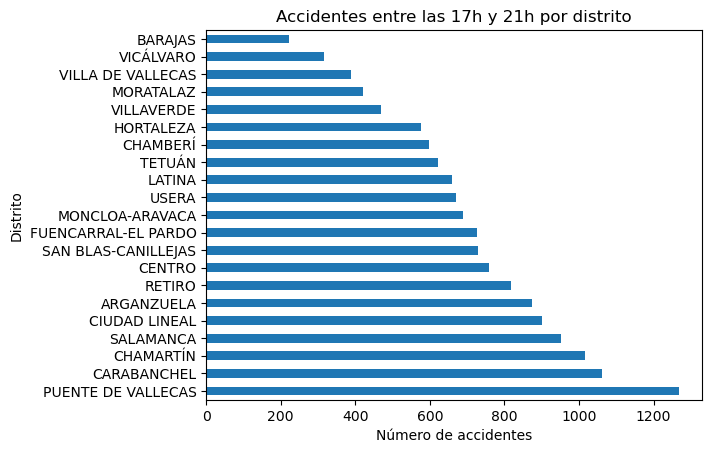

In [54]:
accidentes_por_distrito.plot.barh()
plt.title('Accidentes entre las 17h y 21h por distrito')
plt.xlabel('Número de accidentes')
plt.ylabel('Distrito')
plt.show()

Los accidentes del tramo negro están bastante repartidos por distritos; los que más tienen son **Puente de Vallecas**, **Carabanchel**, **Chamartín** y **Salamanca**.

Vamos a ver si por la localización podemos sacar alguna conclusión.

In [55]:
accidentes_por_localización = tramo_negro['localizacion'].value_counts()

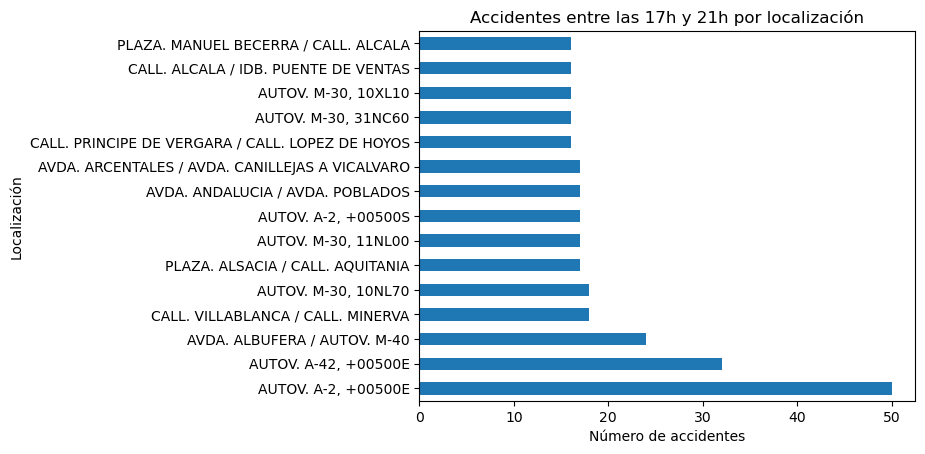

In [56]:
accidentes_por_localización.head(15).plot.barh()
plt.title('Accidentes entre las 17h y 21h por localización')
plt.xlabel('Número de accidentes')
plt.ylabel('Localización')
plt.show()

Aquí vemos que muchos de los puntos con más accidentes en el tramo negro son **autovías** (A-2, A-42, M-30, M-40).

Llama la atención el punto de la **calle Villablanca / Minerva**, ya que no es una autovía sino un cruce de calles.

### Perfil por edad

De cara a mirar el perfil de las personas que tienen accidentes, vamos a ver si hay algún rango de edad dominante.

In [57]:
accidentes_por_edad = tramo_negro['rango_edad'].value_counts()

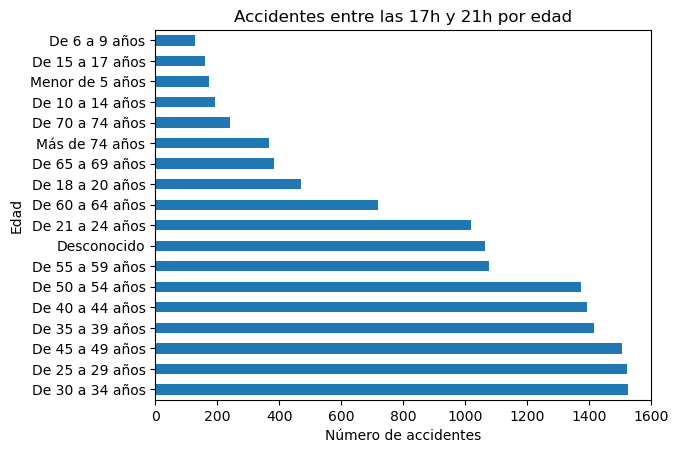

In [58]:
accidentes_por_edad.plot.barh()
plt.title('Accidentes entre las 17h y 21h por edad')
plt.xlabel('Número de accidentes')
plt.ylabel('Edad')
plt.show()

Vemos que los accidentes se producen sobre todo en el tramo de edad **25 - 55**. Teniendo en cuenta que la mayoría de implicados eran conductores, tiene sentido que sean mayores de edad y que sean ellos los que conducían.

### Accidentes por mes

In [59]:
accidentes_por_mes = db['mes'].value_counts().sort_index()

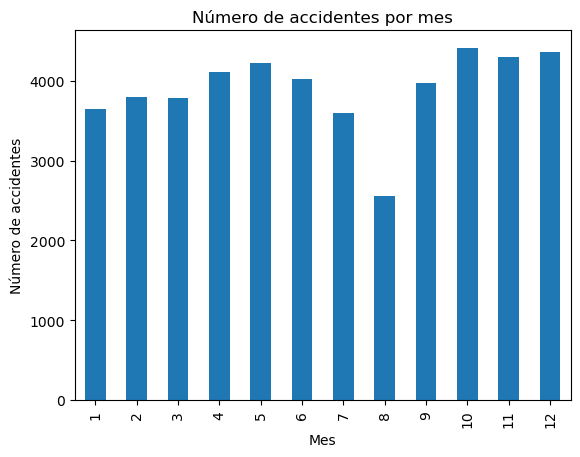

In [60]:
accidentes_por_mes.plot.bar()
plt.title('Número de accidentes por mes')
plt.xlabel('Mes')
plt.ylabel('Número de accidentes')
plt.show()

Por último, vemos que **agosto** es el mes con menos accidentes.

### Tipo de accidente

A continuación vamos a coger los datos totales de tipo de accidente.

In [61]:
db['tipo_accidente'].value_counts()

tipo_accidente
Colisión doble                  21427
Alcance                         11708
Choque contra obstáculo fijo     4682
Atropello a persona              2904
Caída                            2637
Colisión múltiple                2182
Otro                              763
Solo salida de la vía             237
Vuelco                            158
Atropello a animal                 71
Name: count, dtype: int64

In [62]:
accidentes_por_tipoaccidente = tramo_negro['tipo_accidente'].value_counts()

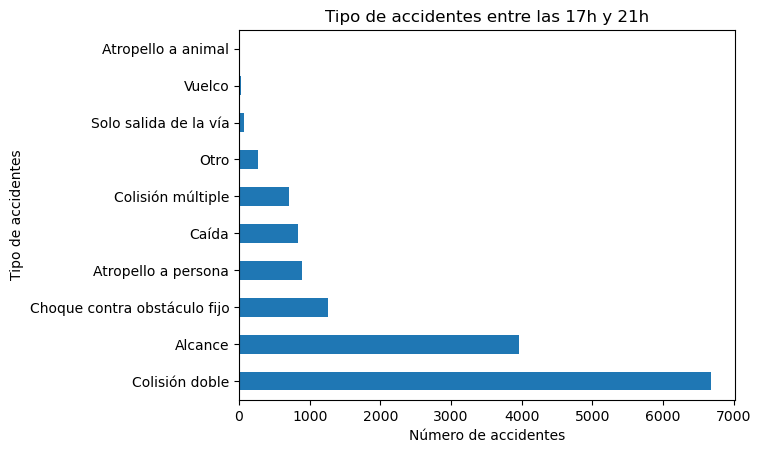

In [63]:
accidentes_por_tipoaccidente.plot.barh()
plt.title('Tipo de accidentes entre las 17h y 21h')
plt.xlabel('Número de accidentes')
plt.ylabel('Tipo de accidentes')
plt.show()

En el tramo negro también predominan las **colisiones dobles** y los **alcances**, como en el total de accidentes.

### Gravedad según el estado meteorológico y el tipo de accidente

Para completar la pregunta de negocio, vemos qué parte de los accidentes son **graves** (ingreso superior a 24 horas o fallecidos) según el estado meteorológico y según el tipo de accidente. Solo usamos los accidentes con dato de lesividad: los de *Se desconoce* contarían como no graves sin saberlo.

In [64]:
# Nos quedamos con los accidentes que tienen dato de lesividad y marcamos los graves
con_lesividad = db[db['lesividad'] != 'Se desconoce'].copy()
con_lesividad['grave'] = con_lesividad['lesividad'].isin(['Ingreso superior a 24 horas', 'Fallecido 24 horas'])

In [65]:
# Accidentes graves y no graves según el estado meteorológico
gravedad_meteo = pd.crosstab(con_lesividad['estado_meteorológico'], con_lesividad['grave'])
gravedad_meteo = gravedad_meteo.rename(columns={False: 'No grave', True: 'Grave'})
gravedad_meteo['% graves'] = gravedad_meteo['Grave'] / (gravedad_meteo['Grave'] + gravedad_meteo['No grave']) * 100
gravedad_meteo.sort_values('% graves')

grave,No grave,Grave,% graves
estado_meteorológico,,,
Granizando,4,0,0.000000
Nevando,1,0,0.000000
LLuvia intensa,294,4,1.342282
Lluvia débil,1398,23,1.618578
Se desconoce,199,4,1.970443
Despejado,22414,509,2.220477
Nublado,1991,49,2.401961


Con **lluvia** no hay más accidentes graves que con el día **despejado** o **nublado**; incluso hay algo menos. Con granizo y nieve hay tan pocos accidentes que no se puede sacar nada. El **estado meteorológico no influye** en la gravedad.

In [66]:
# Lo mismo según el tipo de accidente
gravedad_tipo = pd.crosstab(con_lesividad['tipo_accidente'], con_lesividad['grave'])
gravedad_tipo = gravedad_tipo.rename(columns={False: 'No grave', True: 'Grave'})
gravedad_tipo['% graves'] = gravedad_tipo['Grave'] / (gravedad_tipo['Grave'] + gravedad_tipo['No grave']) * 100
gravedad_tipo.sort_values('% graves')

grave,No grave,Grave,% graves
tipo_accidente,,,
Atropello a animal,23,0,0.000000
Otro,291,1,0.342466
Alcance,6748,47,0.691685
Colisión múltiple,1270,9,0.703675
Colisión doble,11657,225,1.893621
Choque contra obstáculo fijo,1262,40,3.072197
Caída,2305,83,3.475712
Vuelco,106,4,3.636364
Solo salida de la vía,102,6,5.555556


Aquí sí hay diferencias: los **atropellos a personas** son los que más acaban en accidente grave, seguidos de las salidas de la vía, los vuelcos (estos dos con pocos casos) y las caídas. Los **alcances** y las colisiones múltiples apenas tienen graves. El **tipo de accidente sí influye** en la gravedad.

## 6. Pregunta adicional

A priori las conclusiones están bastante claras, pero vamos a solucionar alguna pregunta adicional de las propuestas, ya que pueden ser interesantes:

### ¿Se observa alguna relación entre el estado meteorológico y la lesividad de los accidentes?

In [67]:
db.groupby('lesividad')['estado_meteorológico'].value_counts()

lesividad                                                  estado_meteorológico
Asistencia sanitaria ambulatoria con posterioridad         Despejado                 430
                                                           Nublado                    37
                                                           Lluvia débil               31
                                                           LLuvia intensa             15
                                                           Se desconoce                6
Asistencia sanitaria inmediata en centro de salud o mutua  Despejado                 922
                                                           Nublado                    81
                                                           Lluvia débil               72
                                                           LLuvia intensa             19
                                                           Se desconoce                5
Asistencia sanitaria sólo en e

En todos los tipos de lesividad la mayoría de accidentes se dan con el día **despejado**, pero es porque la mayoría de los accidentes se dan con el día despejado. Para saber si el clima influye hay que mirar el porcentaje de accidentes graves de cada estado meteorológico, como en la tabla del apartado anterior: con lluvia no hay más accidentes graves, así que **el clima no influyó en la lesividad**.

## 7. Conclusiones

- **Franja horaria:** la mayoría de los accidentes se producen por la tarde, y los graves se reparten en tres tramos: 8-9, 12-14 y 18-22. En el **tramo negro (17h - 21h)** se concentra una cuarta parte de los accidentes graves, y los puntos con más accidentes en ese tramo son **autovías** (A-2, A-42, M-30, M-40).
- **Tipo de accidente:** es lo que más influye en la gravedad. Los **atropellos a personas** son los que más acaban en accidente grave (6,4 %), mientras que en los alcances es solo el 0,7 %.
- **Estado meteorológico:** no influye; con lluvia no hay más accidentes graves que con el día despejado.
- **Alcohol:** solo un 3 % de los implicados dio positivo, sobre todo hombres y fuera de las horas centrales del día. La edad tampoco fue determinante.

### Propuesta de acciones

- **Campaña de prevención en las horas con más accidentes graves** (8-9, 12-14 y 18-22), recordando que la mayoría de los accidentes son **colisiones dobles y alcances**.
- **Más vigilancia en las autovías** (A-2, A-42, M-30, M-40) entre las 17 y las 21 horas, que es donde más accidentes hay en el tramo negro.
- **Protección de los peatones:** los atropellos son los accidentes más graves, así que conviene revisar los pasos de peatones y la velocidad en las zonas con más atropellos.
- **Controles de alcoholemia de noche y de madrugada**, que es cuando más positivos hay. El modelo del apartado 8 puede ayudar a decidir cuándo ponerlos.

Línea de mejora: el dataset no recoge la causa de cada accidente; con ese dato se podrían afinar las acciones.

## 8. Modelo de Regresión Logística

**Objetivo:** usar la información preprocesada del EDA para entrenar un modelo de Regresión Logística que prediga si un implicado da **positivo en alcohol** (`positiva_alcohol`) o no.

### Selección y preparación de las variables

In [68]:
db.head(10)

,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,cod_lesividad,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,mes
0,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,Hombre,2,Ingreso inferior o igual a 24 horas,444913.0,4481427.0,N,1
1,14,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión doble,Lluvia débil,Turismo,Conductor,De 55 a 59 años,Mujer,14,Sin asistencia sanitaria,444913.0,4481427.0,N,1
2,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,Hombre,7,Asistencia sanitaria sólo en el lugar del acci...,440123.0,4475170.0,N,2
3,14,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión doble,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,Hombre,14,Sin asistencia sanitaria,440123.0,4475170.0,N,2
4,10,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión doble,Despejado,Turismo,Conductor,De 25 a 29 años,Hombre,77,Se desconoce,440137.0,4475721.0,N,2
5,10,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión doble,Despejado,Turismo,Conductor,De 55 a 59 años,Hombre,77,Se desconoce,440137.0,4475721.0,N,2
6,17,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión doble,Despejado,Camión rígido,Conductor,De 25 a 29 años,Hombre,14,Sin asistencia sanitaria,440709.0,4480102.0,N,2
7,17,"CALL. PINOS ALTA, 93",93,6,TETUÁN,Colisión doble,Despejado,Maquinaria de obras,Conductor,De 50 a 54 años,Hombre,14,Sin asistencia sanitaria,440709.0,4480102.0,N,2
8,14,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Furgoneta,Conductor,De 60 a 64 años,Hombre,77,Se desconoce,433983.0,4468473.0,N,3
9,14,CTRA. BARRIO DE LA FORTUNA / CALL. PINAR DE SA...,14,10,LATINA,Alcance,Lluvia débil,Turismo,Conductor,De 25 a 29 años,Hombre,77,Se desconoce,433983.0,4468473.0,N,3


Hemos visto que solo un 3 % de los implicados dio positivo en alcohol. Pero, ¿qué factores pueden influir en que el resultado sea positivo o negativo? Vamos a proceder a ver algunas variables relacionadas con el alcohol, para poder establecer en nuestro modelo las incluidas en `X`.

Como la mayoría de los datos arrojan que casi siempre el resultado de la prueba es negativo, vamos a crear una variable que contenga únicamente los valores del dataframe donde el resultado fue **sí** (`control_positivo`).

In [69]:
control_positivo = db[(db['positiva_alcohol'] == 'S')]

In [70]:
control_positivo.groupby('estado_meteorológico')['positiva_alcohol'].count()

estado_meteorológico
Despejado         1270
LLuvia intensa       7
Lluvia débil        71
Nublado             74
Se desconoce        10
Name: positiva_alcohol, dtype: int64

La mayoría de positivos se dieron con el día **despejado**, pero es porque la mayoría de los accidentes se dan con el día despejado, así que esto no nos dice que el clima influya. Aun así, lo metemos en el modelo para comprobarlo.

In [71]:
control_positivo.groupby('tipo_accidente')['positiva_alcohol'].count()

tipo_accidente
Alcance                         253
Atropello a persona              49
Caída                           114
Choque contra obstáculo fijo    455
Colisión doble                  435
Colisión múltiple                56
Otro                             10
Solo salida de la vía            37
Vuelco                           23
Name: positiva_alcohol, dtype: int64

Aquí vemos **tres variables predominantes** que nos indican que posiblemente la mayoría de accidentes hayan sido con coches. Si lo verificamos:

In [72]:
control_positivo.groupby('tipo_vehiculo')['positiva_alcohol'].count()

tipo_vehiculo
Autobús                                 2
Autobús articulado                      1
Bicicleta                              16
Bicicleta EPAC (pedaleo asistido)      13
Camión rígido                          12
Ciclomotor                             25
Cuadriciclo ligero                      1
Cuadriciclo no ligero                   1
Furgoneta                             105
Motocicleta > 125cc                    40
Motocicleta hasta 125cc                71
Otros vehículos con motor               4
Sin especificar                         1
Todo terreno                           28
Tractocamión                            1
Turismo                              1062
VMU eléctrico                          49
Name: positiva_alcohol, dtype: int64

Vemos que los **turismos** fueron los que más positivos dieron por amplia mayoría.

In [73]:
control_positivo.groupby('distrito')['positiva_alcohol'].count()

distrito
ARGANZUELA              43
BARAJAS                 13
CARABANCHEL            152
CENTRO                  57
CHAMARTÍN              101
CHAMBERÍ                62
CIUDAD LINEAL           94
FUENCARRAL-EL PARDO     67
HORTALEZA               58
LATINA                 104
MONCLOA-ARAVACA         45
MORATALAZ               34
PUENTE DE VALLECAS     143
RETIRO                  46
SALAMANCA               70
SAN BLAS-CANILLEJAS     57
TETUÁN                  69
USERA                   74
VICÁLVARO               28
VILLA DE VALLECAS       34
VILLAVERDE              81
Name: positiva_alcohol, dtype: int64

El **distrito** no nos muestra ninguna tendencia significante.

In [74]:
control_positivo.groupby('tipo_persona')['positiva_alcohol'].count()

tipo_persona
Conductor    1399
Pasajero       10
Peatón         23
Name: positiva_alcohol, dtype: int64

Casi todos los positivos son de **conductores**. Quizás, más que esto, sería interesante ver el sexo:

In [75]:
control_positivo.groupby('sexo')['positiva_alcohol'].count()

sexo
Hombre    1210
Mujer      222
Name: positiva_alcohol, dtype: int64

Los **hombres** por goleada.

In [76]:
control_positivo.groupby('rango_edad')['positiva_alcohol'].count()

rango_edad
De 15 a 17 años      5
De 18 a 20 años     51
De 21 a 24 años    147
De 25 a 29 años    199
De 30 a 34 años    177
De 35 a 39 años    162
De 40 a 44 años    151
De 45 a 49 años    176
De 50 a 54 años    144
De 55 a 59 años    113
De 60 a 64 años     61
De 65 a 69 años     27
De 70 a 74 años     11
Menor de 5 años      1
Más de 74 años       7
Name: positiva_alcohol, dtype: int64

Predominan las **edades centrales**. Aquí además vemos datos que no cuadran, como por ejemplo el positivo en alcohol de menos de 5 años. No entraremos en ello y no usaremos la edad en el modelo.

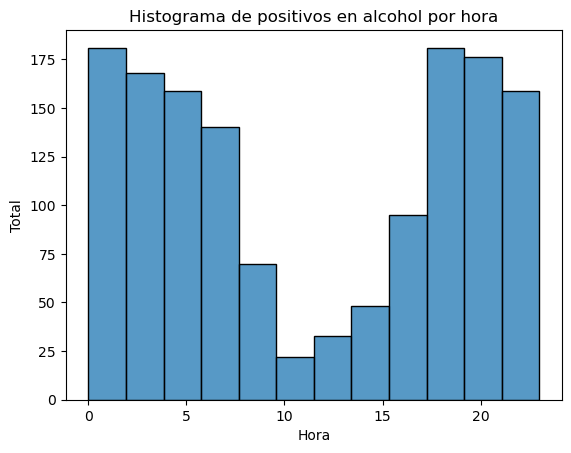

In [77]:
sns.histplot(control_positivo['hora'])
plt.title('Histograma de positivos en alcohol por hora')
plt.xlabel('Hora')
plt.ylabel('Total')
plt.show()

Vemos que los positivos **disminuyen en las horas centrales del día**.

### Variable objetivo (`y`) y variables predictoras (`X`)

Procedemos a poner nuestra variable objetivo (`y`) y a poner las variables que se tendrán en cuenta (`X`).

In [78]:
y = (db['positiva_alcohol'] == 'S').astype(int)

Pasamos la hora a **franjas horarias** (madrugada de 0 a 6, mañana de 7 a 12, tarde de 13 a 20 y noche de 21 a 23). Como número, para el modelo las 23 y las 0 estarían lo más lejos posible, cuando en realidad van seguidas. El **mes** lo trataremos como categoría por lo mismo (diciembre y enero).

In [79]:
db['franja_horaria'] = pd.cut(db['hora'], bins=[-1, 6, 12, 20, 23], labels=['Madrugada', 'Mañana', 'Tarde', 'Noche'])

In [80]:
X = db[['tipo_accidente', 'franja_horaria', 'sexo', 'tipo_vehiculo', 'estado_meteorológico', 'mes']]

### Entrenamiento y evaluación

División 80% / 20% en entrenamiento y prueba, y uso de la clase `AlcoholLogisticModel` definida en `models.py`. La clase lleva un **pipeline** con dos pasos:

- **OneHotEncoder:** codifica las categorías como columnas de 0/1, sin orden artificial. Al estar dentro del pipeline, solo aprende del entrenamiento.
- **Regresión Logística** con `class_weight='balanced'`, para dar más peso a los positivos, que son muy pocos.

No escalamos las variables: todas acaban siendo columnas de 0/1, que ya están en la misma escala.

In [81]:
# stratify=y: como solo hay un 3 % de positivos, así entrenamiento y prueba tienen la misma proporción de positivos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [82]:
RegLogAl = AlcoholLogisticModel(X_train, X_test, y_train, y_test)

In [83]:
RegLogAl.fit()

In [84]:
RegLogAl.predict()

array([0, 1, 0, ..., 1, 0, 0])

Accuracy: 0.8000855249091298
              precision    recall  f1-score   support

           0       0.99      0.80      0.89      9068
           1       0.10      0.68      0.17       286

    accuracy                           0.80      9354
   macro avg       0.54      0.74      0.53      9354
weighted avg       0.96      0.80      0.86      9354



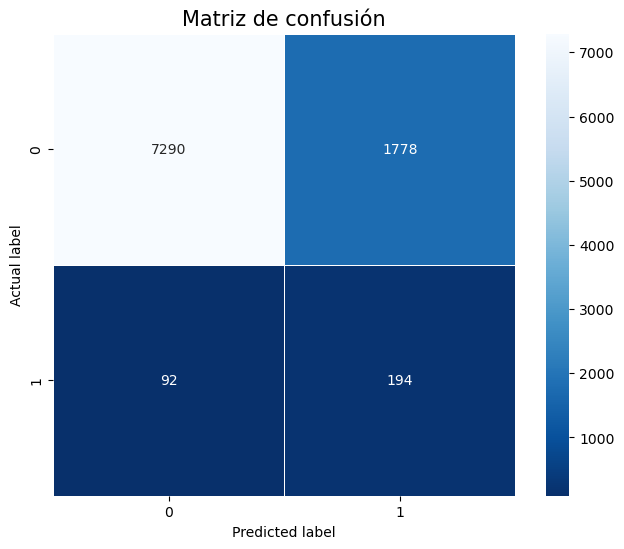

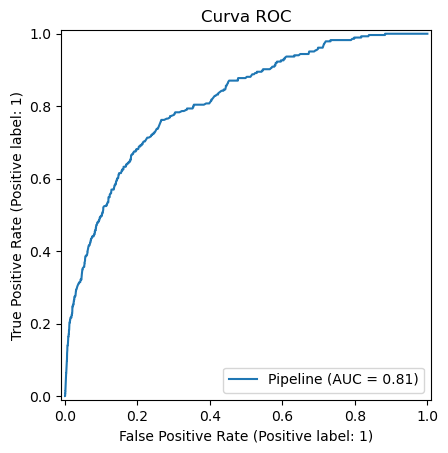

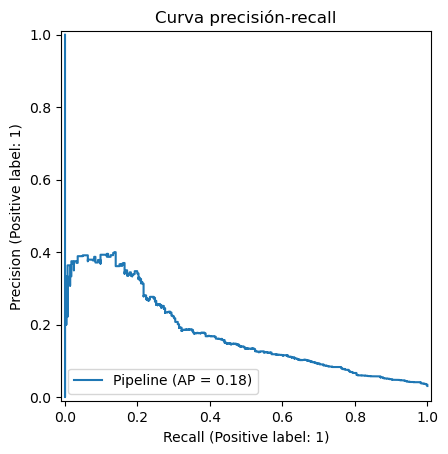

In [85]:
RegLogAl.evaluate()

El accuracy baja a 0,80, pero ahora el modelo **sí detecta positivos**: encuentra 194 de los 286 positivos de la prueba (**recall de 0,68**). A cambio, da muchas falsas alarmas: de los que marca como positivos, solo 1 de cada 10 lo es de verdad (**precisión de 0,10**).

La **curva ROC** (AUC de 0,81) muestra que el modelo distingue bastante bien a los positivos de los negativos. La **curva precisión-recall** (AP de 0,18) muestra que, con tan pocos positivos, es difícil encontrarlos sin muchas falsas alarmas.

Aun así, es mucho más útil que un modelo que diga siempre «negativo», que acertaría el 97 % de las veces sin detectar ningún positivo.

### Coeficientes del modelo

Vemos qué categorías suben (coeficiente positivo) o bajan (coeficiente negativo) la probabilidad de dar positivo en alcohol.

In [86]:
coeficientes = pd.Series(RegLogAl.model['regresion'].coef_[0],
                         index=RegLogAl.model['codificacion'].get_feature_names_out())
coeficientes = coeficientes.sort_values()

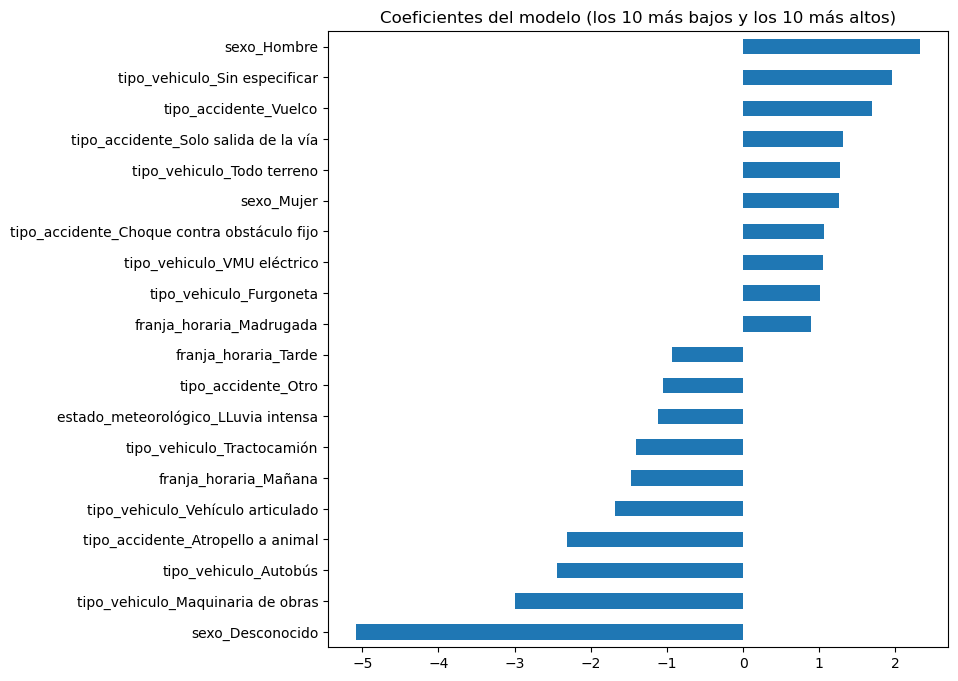

In [87]:
pd.concat([coeficientes.head(10), coeficientes.tail(10)]).plot.barh(figsize=(8, 8))
plt.title('Coeficientes del modelo (los 10 más bajos y los 10 más altos)')
plt.show()

Los coeficientes cuadran con lo que vimos en el EDA:

- Ser **hombre** es lo que más sube la probabilidad de positivo.
- La **madrugada** la sube, y la **mañana** y la **tarde** la bajan, como en el histograma de positivos por hora.
- Los **vuelcos**, las **salidas de la vía** y los **choques contra obstáculo fijo** la suben.
- Los vehículos profesionales (autobús, maquinaria de obras, vehículo articulado, tractocamión) la bajan.
- El sexo *Desconocido* es lo que más la baja: en el EDA no había ningún positivo con sexo desconocido.

### Guardado y carga del modelo

In [88]:
# Guardamos el modelo
RegLogAl.save_model('fernando_modelo.pkl')

In [89]:
# Cargamos el modelo guardado
RegLogAl.load_model('fernando_modelo.pkl')